# Preliminary evaluation on our test Mels

Before optimizing our model, we performed a preliminary evaluation of its ability to predict our soundscape taxonomy using the 380 mel-spectrograms reserved for testing.

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2
from uvne_packs.losses import FocalLossMultilabel
import numpy as np
from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    hamming_loss,
    accuracy_score
)
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix

%env CUDA_DEVICE_ORDER=PCI_BUS_ID
%env CUDA_VISIBLE_DEVICES=1

import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1" # Disable GPU
import pandas as pd


AUTOTUNE = tf.data.experimental.AUTOTUNE

tf.__version__
tf.keras.__file__

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


env: CUDA_DEVICE_ORDER=PCI_BUS_ID
env: CUDA_VISIBLE_DEVICES=1


In [2]:
# use Metropolis when it needed
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager as font_manager

font_path = r"C:/Users/Acer/AppData/Local/Microsoft/Windows/Fonts/"

metropolis_fonts = {
    "regular": "Metropolis-Regular.otf",
    "bold": "Metropolis-Bold.otf",
    "semibold": "Metropolis-SemiBold.otf",
    "light": "Metropolis-Light.otf",
    "medium": "Metropolis-Medium.otf",
    "black": "Metropolis-Black.otf",
    "extrabold": "Metropolis-ExtraBold.otf",
    "italic": "Metropolis-RegularItalic.otf"
}

# dictionary for FontProperties
metro = {}

for style, filename in metropolis_fonts.items():
    fullpath = os.path.join(font_path, filename)
    if os.path.exists(fullpath):
        font_manager.fontManager.addfont(fullpath)
        metro[style] = FontProperties(fname=fullpath)
    else:
        print(f"⚠️ Not found {filename}")

# 0. Basic setup

In [21]:
# PATHS

# PATHS TO SAVE MODEL (.keras)
SAVE_DIR_K_2 = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\2_cnn_training-py\results\k_135_2"
BEST_MODEL_PATH_K_2 = os.path.join(SAVE_DIR_K_2, "best_model_finetuned.keras")

ORG_LABELS_TEST = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\test_df_pb.csv"
ORG_TEST_DIR = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\test_mels_pb"

# TEST

test_df = pd.read_csv(ORG_LABELS_TEST)
test_df["png_filename"] = test_df["filename"].str.replace(".wav", ".png", regex=False)

print("✅ test_df cargado:", test_df.shape)
display(test_df.sample(5))

✅ test_df cargado: (380, 11)


,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI,png_filename
170,048_41_P2.wav,0,0,0,0,1,0,0,0,0,048_41_P2.png
161,045_31_P1.wav,0,1,1,0,0,0,0,0,0,045_31_P1.png
11,003_36_P2.wav,0,0,0,0,0,0,0,0,1,003_36_P2.png
175,050_32_P2.wav,0,0,1,0,0,0,0,0,0,050_32_P2.png
333,091_37_P1.wav,0,1,1,0,0,0,0,0,0,091_37_P1.png


In [4]:
CLASS_NAMES = ["TM","MH","VO","MU","EM","SO","BI","GE","SI"]
N_CLASSES = len(CLASS_NAMES)
N_CLASSES

9

In [5]:
# TRAINING PARAMETERS

BATCH_SIZE = 64
IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_DEPTH  = 3

In [6]:
test_label_lookup = {
    row["png_filename"]: row[CLASS_NAMES].values.astype("float32")
    for _, row in test_df.iterrows()
}

print("✅ Entradas en test_label_lookup:", len(test_label_lookup))

✅ Entradas en test_label_lookup: 380


### Functions

In [7]:
# PROCESS PATH

def process_path(file_path, IMG_HEIGHT, IMG_WIDTH):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)
    img = tf.image.resize(img, [IMG_HEIGHT, IMG_WIDTH])
    return img

In [8]:
# DECODE IMAGES OF MELS SPECTROGRAMS

def decode_img(img):
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)
    img = tf.image.resize(img, [IMG_HEIGHT, IMG_WIDTH])
    return img

In [9]:
# LOOK UP

def lookup_label_from_path(path, lookup_dict):
    fname = path.numpy().decode()
    fname = os.path.basename(fname)
    return lookup_dict[fname]

In [10]:
# LOAD MELS AND LABELS

def load_png_and_label(path, lookup_dict):

    label = tf.py_function(
        func=lambda p: lookup_label_from_path(p, lookup_dict),
        inp=[path],
        Tout=tf.float32
    )
    label.set_shape((len(CLASS_NAMES),))

    raw = tf.io.read_file(path)
    img = decode_img(raw)
    img.set_shape((IMG_HEIGHT, IMG_WIDTH, 3))

    return img, label


In [11]:
# CALCULATE PROBABILITIES FROM LOGITS

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

In [12]:
# GET CLASSES COMBINATIONS

def build_comb_label(row):
    active = [cls for cls in CLASS_NAMES if row[cls] == 1]
    return "+".join(active) if active else "none"

In [13]:
# COUNT FOR BAR PLOTS

def add_bar_labels(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{int(height)}",
            ha="center",
            va="bottom",
            fontproperties=metro["regular"],
            fontsize=10
        )

In [14]:
# EVALUATE LOGITS FOR BI AND GE

def evaluate_subset(name, mask, class_idx, class_name):
    gt = y_true[mask, class_idx]
    lg = y_logits[mask, class_idx]
    pred = (lg >= 0).astype(int)

    if len(gt) == 0:
        print(f"\n⚠️ {name}: no samples")
        return

    prec = precision_score(gt, pred, zero_division=0)
    rec  = recall_score(gt, pred, zero_division=0)
    f1   = f1_score(gt, pred, zero_division=0)

    print("\n" + "="*70)
    print(f"{class_name} EVALUATION — {name}")
    print("="*70)
    print(f"Samples        : {len(gt)}")
    print(f"Precision      : {prec:.3f}")
    print(f"Recall         : {rec:.3f}")
    print(f"F1             : {f1:.3f}")
    print(f"Logits mean    : {lg.mean():.3f} ± {lg.std():.3f}")
    print(f"Logits min/max : {lg.min():.3f} / {lg.max():.3f}")

    plt.figure(figsize=(7, 4))

    # positives
    pos = lg[gt == 1]


    # adjust closed logits bars for correct visualization
    if len(pos) > 1 and np.ptp(pos) < 0.01:
        center = pos.mean()
        forced_range = (center - 0.05, center + 0.05)

        plt.hist(
            pos,
            bins=1,
            range=forced_range,
            alpha=0.6,
            color="#7f00ff",
            label=f"GT {class_name} = 1 (forced range)"
        )
    else:
        # rest with normal behaivor
        plt.hist(
            pos,
            bins=30,
            alpha=0.6,
            color="#7f00ff",
            label=f"GT {class_name} = 1"
        )

    plt.axvline(0, color="black", linestyle="--", linewidth=1)

    plt.title(
        f"{class_name} logits — {name}",
        fontproperties=metro["bold"],
        fontsize=12
    )
    plt.xlabel("Logit", fontproperties=metro["regular"])
    plt.ylabel("Count", fontproperties=metro["regular"])
    plt.legend()
    plt.tight_layout()
    plt.show()

In [15]:
# DIAGNOSE LOGIT PER CLASS

def diagnose_logits_per_class(y_true, y_logits, class_names):
    for i, cls in enumerate(class_names):
        gt = y_true[:, i]
        lg = y_logits[:, i]

        pos = lg[gt == 1]
        neg = lg[gt == 0]

        print("\n" + "="*70)
        print(f"CLASS: {cls}")
        print("="*70)
        print(f"Positives: {len(pos)} | Negatives: {len(neg)}")
        print(f"Logits (pos): mean={pos.mean():.3f}, std={pos.std():.3f}, min={pos.min():.3f}, max={pos.max():.3f}")
        print(f"Logits (neg): mean={neg.mean():.3f}, std={neg.std():.3f}, min={neg.min():.3f}, max={neg.max():.3f}")

        if len(pos) > 0 and len(neg) > 0:
            auc = roc_auc_score(gt, lg)
            print(f"AUC (logits): {auc:.4f}")
        else:
            print("AUC: not computable")

        plt.figure(figsize=(8, 4))

        plt.hist(
            neg,
            bins=50,
            alpha=0.6,
            label="Negative",
            color="#ff6ec7"
        )

        plt.hist(
            pos,
            bins=50,
            alpha=0.6,
            label="Positive",
            color="#7f00ff"
        )

        plt.axvline(0, color="black", linestyle="--", linewidth=1)

        plt.title(
            f"Logit distribution — {cls}",
            fontproperties=metro["bold"],
            fontsize=13
        )

        plt.xlabel(
            "Logit value",
            fontproperties=metro["regular"],
            fontsize=11
        )

        plt.ylabel(
            "Count",
            fontproperties=metro["regular"],
            fontsize=11
        )

        legend = plt.legend()
        for text in legend.get_texts():
            text.set_fontproperties(metro["regular"])

        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()


# 1. Prepare test Mels

In [16]:
# COUNT TEST MELS

# ALLOWING OVERLAP
count_present = {
    cls: test_df[cls].sum()
    for cls in CLASS_NAMES
}

# IN ISOLATION
count_isolated = {}

for cls in CLASS_NAMES:
    others = [c for c in CLASS_NAMES if c != cls]

    isolated_mask = (
        (test_df[cls] == 1) &
        (test_df[others].sum(axis=1) == 0)
    )

    count_isolated[cls] = isolated_mask.sum()

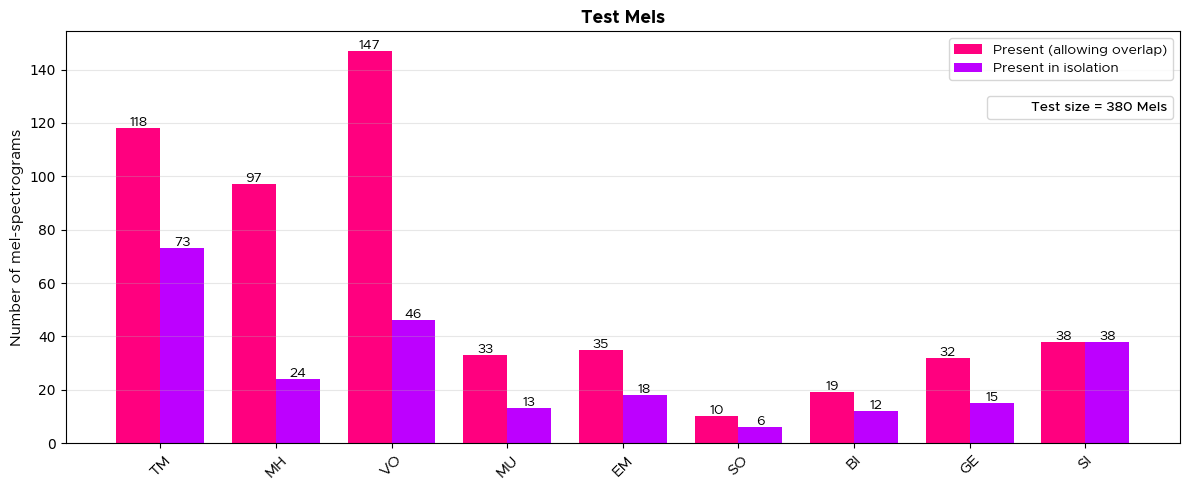

In [17]:
# TEST MELS DISTRIBUTION PLOT

total_test_mels = len(test_df)

total_vals = [count_present[c] for c in CLASS_NAMES]
isolated_vals = [count_isolated[c] for c in CLASS_NAMES]

x = np.arange(len(CLASS_NAMES))
width = 0.38

plt.figure(figsize=(12, 5))

bars_total = plt.bar(
    x - width / 2,
    total_vals,
    width,
    label="Present (allowing overlap)",
    color="#ff007f"
)

bars_isolated = plt.bar(
    x + width / 2,
    isolated_vals,
    width,
    label="Present in isolation",
    color="#bd00ff"
)

for bars in (bars_total, bars_isolated):
    for bar in bars:
        h = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            h,
            f"{int(h)}",
            ha="center",
            va="bottom",
            fontproperties=metro["regular"],
            fontsize=10
        )

plt.xticks(
    x,
    CLASS_NAMES,
    fontproperties=metro["regular"],
    fontsize=11,
    rotation=45
)

plt.ylabel(
    "Number of mel-spectrograms",
    fontproperties=metro["regular"],
    fontsize=11
)

plt.title(
    "Test Mels",
    fontproperties=metro["bold"],
    fontsize=13
)

legend_main = plt.legend(loc="upper right")
for t in legend_main.get_texts():
    t.set_fontproperties(metro["regular"])

dummy = mpatches.Patch(
    color="none",
    label=f"Test size = {total_test_mels} Mels"
)

legend_info = plt.legend(
    handles=[dummy],
    loc="upper right",
    bbox_to_anchor=(1.0, 0.86)
)

for t in legend_info.get_texts():
    t.set_fontproperties(metro["medium"])

plt.gca().add_artist(legend_main)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
test_png_filenames = [
    f for f in test_df["png_filename"].values
    if os.path.exists(os.path.join(ORG_TEST_DIR, f))
]

print("✅  Mels en test:", len(test_png_filenames))

test_png_paths = [
    os.path.join(ORG_TEST_DIR, f)
    for f in test_png_filenames
]

test_list_ds = tf.data.Dataset.from_tensor_slices(test_png_paths)

print("\n✅ Test paths:")
for f in test_list_ds.take(5):
    print(f.numpy().decode())

✅  Mels en test: 380

✅ Test paths:
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\test_mels_pb\001_18_P1.png
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\test_mels_pb\001_35_P1.png
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\test_mels_pb\001_20_P2.png
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\test_mels_pb\001_34_P2.png
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\test_mels_pb\002_20_P1.png


In [19]:
test_ds = test_list_ds.map(
    lambda p: load_png_and_label(p, test_label_lookup),
    num_parallel_calls=AUTOTUNE
)

test_ds = test_ds.batch(32).prefetch(AUTOTUNE)

print("✅ test_ds created.")

✅ test_ds created.


# 2. Confusion matrices

In [22]:
# LOAD MODEL

model = keras.models.load_model(BEST_MODEL_PATH_K_2)

print("✅ Model loaded corrected.")

✅ Model loaded corrected.


In [23]:
# EVALUATION IN LOGITS

y_true = []
y_logits = []

for batch_imgs, batch_labels in test_ds:
    logits = model.predict(batch_imgs, verbose=0)  # LOGITS
    y_true.append(batch_labels.numpy())
    y_logits.append(logits)

y_true = np.concatenate(y_true, axis=0)
y_logits = np.concatenate(y_logits, axis=0)
y_logits_bin = (y_logits >= 0.0).astype(int)


print("✅ Predictions completed.")
print("→ y_true shape:", y_true.shape)
print("→ y_pred shape:", y_logits.shape)

✅ Predictions completed.
→ y_true shape: (380, 9)
→ y_pred shape: (380, 9)


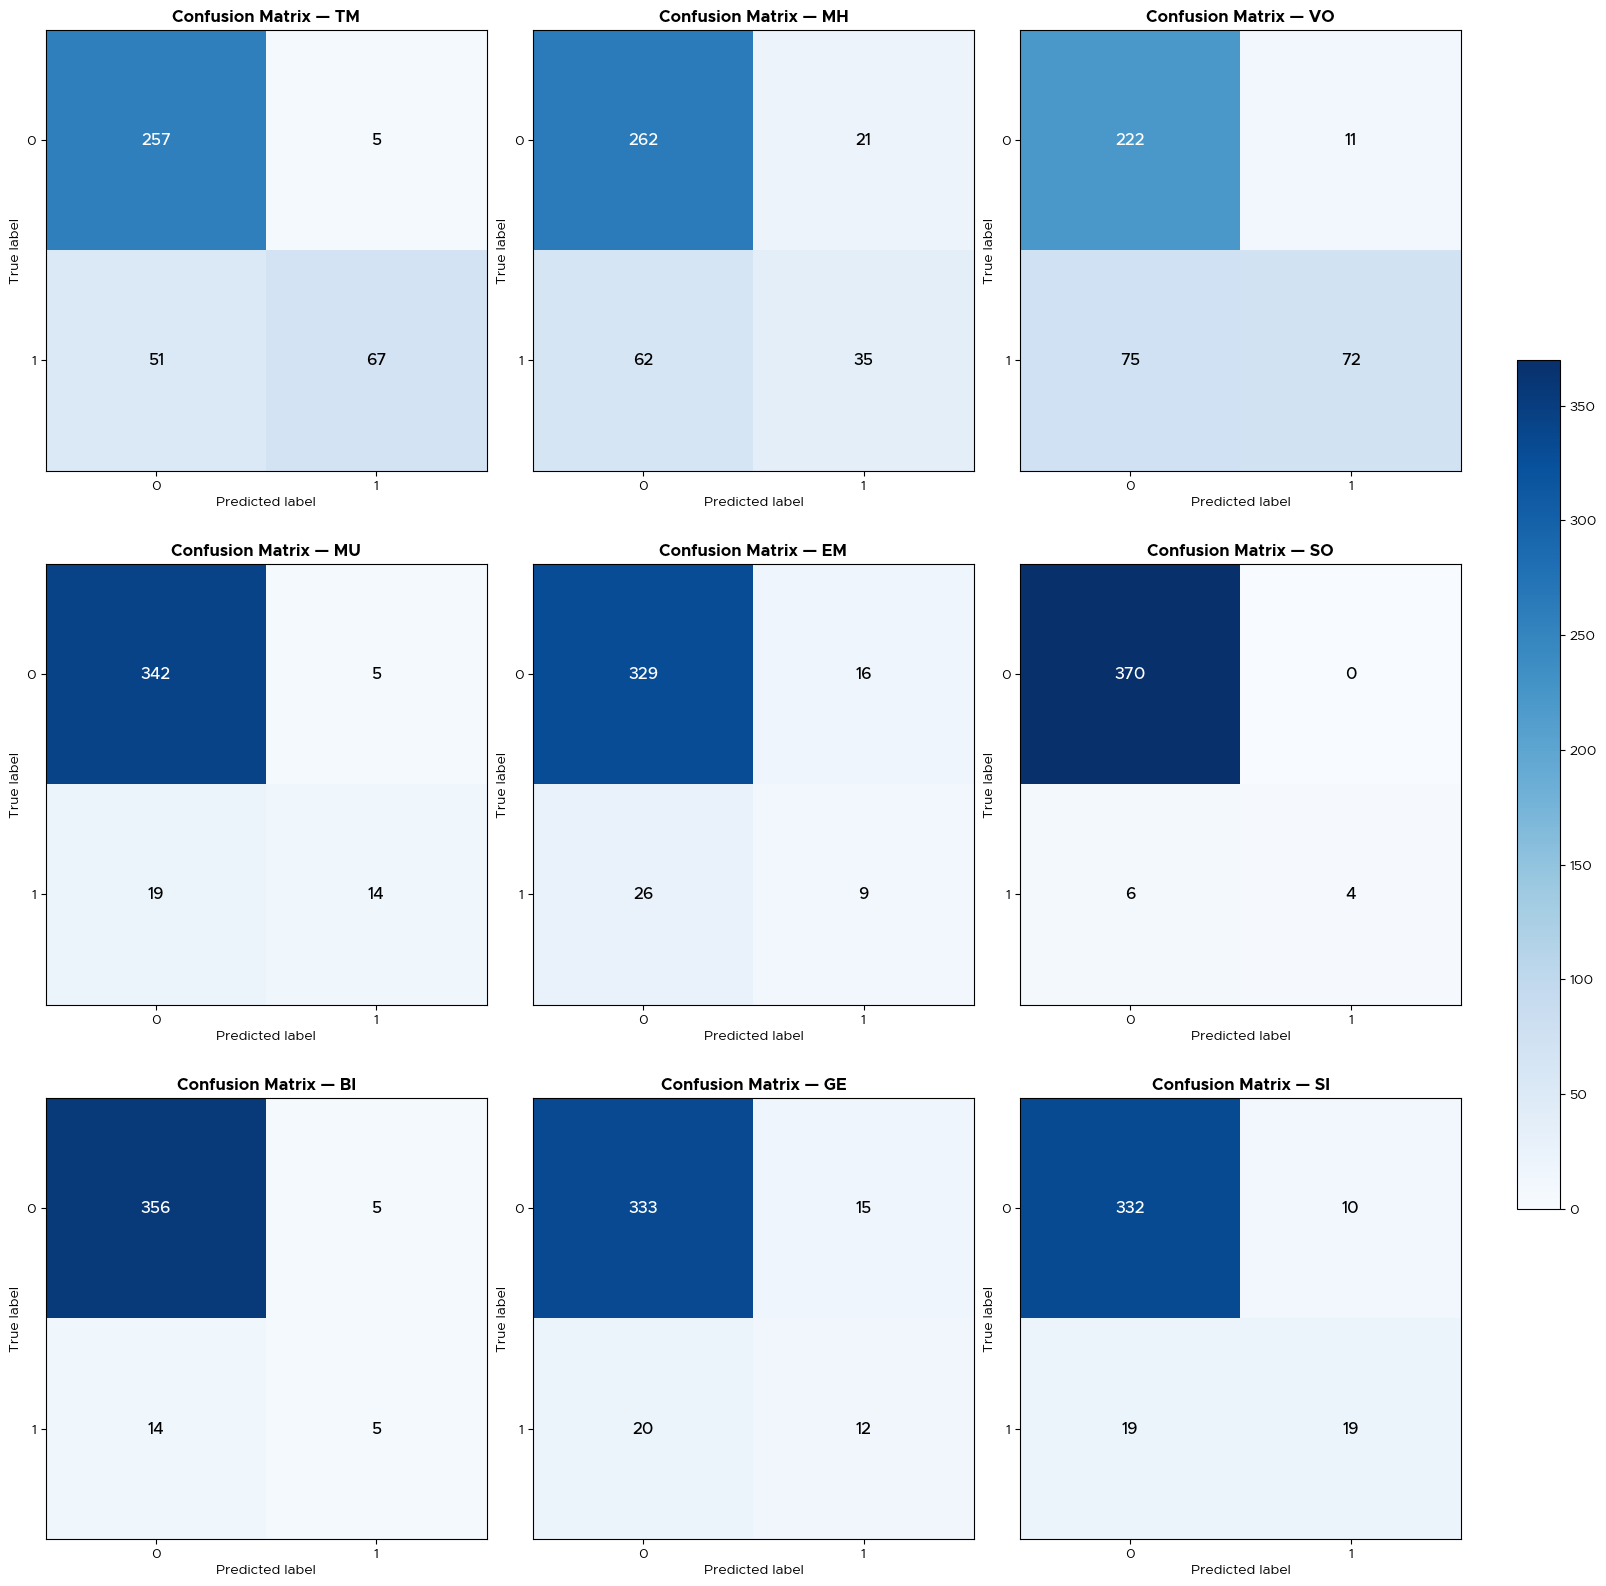

In [24]:
# CONFUSION MATRICES

global_max = max(
    confusion_matrix(y_true[:, i], y_logits_bin[:, i]).max()
    for i in range(len(CLASS_NAMES))
)

fig, axes = plt.subplots(
    3, 3,
    figsize=(16, 16),
    constrained_layout=True
)
axes = axes.ravel()

for i, ax in enumerate(axes):

    cm = confusion_matrix(y_true[:, i], y_logits_bin[:, i])
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=global_max)

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["0", "1"], fontproperties=metro["regular"], fontsize=10)
    ax.set_yticklabels(["0", "1"], fontproperties=metro["regular"], fontsize=10)

    ax.set_xlabel("Predicted label", fontproperties=metro["regular"], fontsize=10)
    ax.set_ylabel("True label", fontproperties=metro["regular"], fontsize=10)

    ax.set_title(
        f"Confusion Matrix — {CLASS_NAMES[i]}",
        fontproperties=metro["bold"],
        fontsize=12
    )

    threshold = global_max / 2.0

    for (row, col), value in np.ndenumerate(cm):
        ax.text(
            col,
            row,
            f"{value}",
            ha="center",
            va="center",
            fontsize=12,
            fontproperties=metro["medium"],
            color="white" if value > threshold else "black"
        )

cbar = fig.colorbar(
    im,
    ax=axes,
    shrink=0.6,
    fraction=0.03,
    pad=0.04
)

for tick in cbar.ax.get_yticklabels():
    tick.set_fontproperties(metro["regular"])
    tick.set_fontsize(10)

plt.show()


In [25]:
# GLOBAL METRICS

metrics_globales = {
    
    "Macro Precision": precision_score(y_true, y_logits_bin, average="macro", zero_division=0),
    "Macro Recall": recall_score(y_true, y_logits_bin, average="macro", zero_division=0),
    "Macro F1": f1_score(y_true, y_logits_bin, average="macro", zero_division=0),

    "Hamming Loss": hamming_loss(y_true, y_logits_bin),
    "Exact Match Ratio": accuracy_score(y_true, y_logits_bin)
}

for k, v in metrics_globales.items():
    print(f"{k:20s}: {v:.4f}")

Macro Precision     : 0.6799
Macro Recall        : 0.4042
Macro F1            : 0.5019
Hamming Loss        : 0.1111
Exact Match Ratio   : 0.3368


In [26]:
# METRICS PER CLASS

class_report = classification_report(
    y_true, 
    y_logits_bin, 
    target_names=CLASS_NAMES,
    zero_division=0,
    output_dict=True
)

df_report = pd.DataFrame(class_report).transpose()
display(df_report)

,precision,recall,f1-score,support
TM,0.930556,0.567797,0.705263,118.0
MH,0.625000,0.360825,0.457516,97.0
VO,0.867470,0.489796,0.626087,147.0
MU,0.736842,0.424242,0.538462,33.0
EM,0.360000,0.257143,0.300000,35.0
SO,1.000000,0.400000,0.571429,10.0
BI,0.500000,0.263158,0.344828,19.0
GE,0.444444,0.375000,0.406780,32.0
SI,0.655172,0.500000,0.567164,38.0
micro avg,0.729231,0.448015,0.555035,529.0
